##**Loan Default Risk Analysis and Prediction Using R**

###Install and Load Required Packages

In [ ]:
required_packages <- c("dplyr", "ggplot2", "corrplot")



library(dplyr)
library(ggplot2)
library(corrplot)

cat("All packages loaded successfully.\n")

All packages loaded successfully.


###Import Credit Risk Dataset

In [ ]:
#Import Credit Risk Dataset
file_path <- "/content/credit_risk_dataset.csv"

if (!file.exists(file_path)) {
  stop("Dataset not found. Upload credit_risk_dataset.csv using the Colab Files panel.")
}

loan_data <- read.csv(file_path, stringsAsFactors = FALSE)

cat("Dataset imported successfully.\n")
cat("Rows:", nrow(loan_data), "\n")
cat("Columns:", ncol(loan_data), "\n")

head(loan_data)

Dataset imported successfully.
Rows: 32581 
Columns: 12 


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
,<int>,<int>,<chr>,<dbl>,<chr>,<chr>,<int>,<dbl>,<int>,<dbl>,<chr>,<int>
1,22,59000,RENT,123,PERSONAL,D,35000,16.02,1,0.59,Y,3
2,21,9600,OWN,5,EDUCATION,B,1000,11.14,0,0.10,N,2
3,25,9600,MORTGAGE,1,MEDICAL,C,5500,12.87,1,0.57,N,3
4,23,65500,RENT,4,MEDICAL,C,35000,15.23,1,0.53,N,2
5,24,54400,RENT,8,MEDICAL,C,35000,14.27,1,0.55,Y,4
6,21,9900,OWN,2,VENTURE,A,2500,7.14,1,0.25,N,2


###Initial Data Inspection and Summary Statistics

In [ ]:
#Initial Data Inspection and Summary Statistics


# First six rows
head(loan_data)

# Dataset dimensions
dim(loan_data)

# Column names and data types
str(loan_data)

# Summary statistics
summary(loan_data)

# Missing values per column
colSums(is.na(loan_data))

# Target distribution
table(loan_data$loan_status)

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
,<int>,<int>,<chr>,<dbl>,<chr>,<chr>,<int>,<dbl>,<int>,<dbl>,<chr>,<int>
1,22,59000,RENT,123,PERSONAL,D,35000,16.02,1,0.59,Y,3
2,21,9600,OWN,5,EDUCATION,B,1000,11.14,0,0.10,N,2
3,25,9600,MORTGAGE,1,MEDICAL,C,5500,12.87,1,0.57,N,3
4,23,65500,RENT,4,MEDICAL,C,35000,15.23,1,0.53,N,2
5,24,54400,RENT,8,MEDICAL,C,35000,14.27,1,0.55,Y,4
6,21,9900,OWN,2,VENTURE,A,2500,7.14,1,0.25,N,2


[1] 32581    12

'data.frame':	32581 obs. of  12 variables:
 $ person_age                : int  22 21 25 23 24 21 26 24 24 21 ...
 $ person_income             : int  59000 9600 9600 65500 54400 9900 77100 78956 83000 10000 ...
 $ person_home_ownership     : chr  "RENT" "OWN" "MORTGAGE" "RENT" ...
 $ person_emp_length         : num  123 5 1 4 8 2 8 5 8 6 ...
 $ loan_intent               : chr  "PERSONAL" "EDUCATION" "MEDICAL" "MEDICAL" ...
 $ loan_grade                : chr  "D" "B" "C" "C" ...
 $ loan_amnt                 : int  35000 1000 5500 35000 35000 2500 35000 35000 35000 1600 ...
 $ loan_int_rate             : num  16 11.1 12.9 15.2 14.3 ...
 $ loan_status               : int  1 0 1 1 1 1 1 1 1 1 ...
 $ loan_percent_income       : num  0.59 0.1 0.57 0.53 0.55 0.25 0.45 0.44 0.42 0.16 ...
 $ cb_person_default_on_file : chr  "Y" "N" "N" "N" ...
 $ cb_person_cred_hist_length: int  3 2 3 2 4 2 3 4 2 3 ...


   person_age     person_income     person_home_ownership person_emp_length
 Min.   : 20.00   Min.   :   4000   Length   :32581       Min.   :  0.00   
 1st Qu.: 23.00   1st Qu.:  38500   N.unique :    4       1st Qu.:  2.00   
 Median : 26.00   Median :  55000   N.blank  :    0       Median :  4.00   
 Mean   : 27.73   Mean   :  66075   Min.nchar:    3       Mean   :  4.79   
 3rd Qu.: 30.00   3rd Qu.:  79200   Max.nchar:    8       3rd Qu.:  7.00   
 Max.   :144.00   Max.   :6000000                         Max.   :123.00   
                                                          NAs    :895      
    loan_intent        loan_grade      loan_amnt     loan_int_rate  
 Length   :32581   Length   :32581   Min.   :  500   Min.   : 5.42  
 N.unique :    6   N.unique :    7   1st Qu.: 5000   1st Qu.: 7.90  
 N.blank  :    0   N.blank  :    0   Median : 8000   Median :10.99  
 Min.nchar:    7   Min.nchar:    1   Mean   : 9589   Mean   :11.01  
 Max.nchar:   17   Max.nchar:    1   3rd Qu.:12

person_age              person_income 
                         0                          0 
     person_home_ownership          person_emp_length 
                         0                        895 
               loan_intent                 loan_grade 
                         0                          0 
                 loan_amnt              loan_int_rate 
                         0                       3116 
               loan_status        loan_percent_income 
                         0                          0 
 cb_person_default_on_file cb_person_cred_hist_length 
                         0                          0


    0     1 
25473  7108 

##Data Quality Checks — Duplicates, Outliers and Unusual Values

In [ ]:
#Data Quality Checks — Duplicates, Outliers and Unusual Values

# Number of exact duplicate rows
sum(duplicated(loan_data))

# Age
summary(loan_data$person_age)
sum(loan_data$person_age > 80, na.rm = TRUE)

# Employment length
summary(loan_data$person_emp_length)
sum(loan_data$person_emp_length > 50, na.rm = TRUE)

# Income
summary(loan_data$person_income)

# Loan amount
summary(loan_data$loan_amnt)

# Interest rate
summary(loan_data$loan_int_rate)

[1] 165

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  20.00   23.00   26.00   27.73   30.00  144.00 

[1] 7

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max.     NAs 
   0.00    2.00    4.00    4.79    7.00  123.00     895 

[1] 2

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
   4000   38500   55000   66075   79200 6000000 

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
    500    5000    8000    9589   12200   35000 

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max.     NAs 
   5.42    7.90   10.99   11.01   13.47   23.22    3116 

##Inspect Unusual Records

In [ ]:
# People older than 80
loan_data[
  loan_data$person_age > 80,
  c("person_age", "person_emp_length", "person_income")
]

# Employment length above 50 years
loan_data[
  !is.na(loan_data$person_emp_length) &
    loan_data$person_emp_length > 50,
  c("person_age", "person_emp_length", "person_income")
]

,person_age,person_emp_length,person_income
,<int>,<dbl>,<int>
82,144,4,250000
184,144,4,200000
576,123,2,80004
748,123,7,78000
32298,144,12,6000000
32417,94,1,24000
32507,84,2,94800


,person_age,person_emp_length,person_income
,<int>,<dbl>,<int>
1,22,123,59000
211,21,123,192000


##Data Cleaning — Remove Duplicates and Invalid Values

In [ ]:
# Start from the original dataset
loan_clean <- loan_data

# Remove exact duplicate rows
loan_clean <- loan_clean[!duplicated(loan_clean), ]

# Remove ages above 100
loan_clean <- loan_clean[loan_clean$person_age <= 100, ]

# Remove employment lengths above 50, keeping missing values
loan_clean <- loan_clean[
  is.na(loan_clean$person_emp_length) |
    loan_clean$person_emp_length <= 50,
]

cat("Cleaning completed.\n")
cat("Original rows:", nrow(loan_data), "\n")
cat("Cleaned rows:", nrow(loan_clean), "\n")
cat("Columns:", ncol(loan_clean), "\n")

Cleaning completed.
Original rows: 32581 
Cleaned rows: 32409 
Columns: 12 


##Verify Cleaned Dataset

In [ ]:
# Confirm cleaned dimensions
dim(loan_clean)

# Remaining missing values
colSums(is.na(loan_clean))

# Check age range
summary(loan_clean$person_age)

# Check employment length
summary(loan_clean$person_emp_length)

# Confirm no duplicate rows remain
sum(duplicated(loan_clean))

[1] 32409    12

person_age              person_income 
                         0                          0 
     person_home_ownership          person_emp_length 
                         0                        887 
               loan_intent                 loan_grade 
                         0                          0 
                 loan_amnt              loan_int_rate 
                         0                       3094 
               loan_status        loan_percent_income 
                         0                          0 
 cb_person_default_on_file cb_person_cred_hist_length 
                         0                          0

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  20.00   23.00   26.00   27.73   30.00   94.00 

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max.     NAs 
  0.000   2.000   4.000   4.783   7.000  41.000     887 

[1] 0

##Convert Categorical Variables into Factors

In [ ]:
loan_clean$person_home_ownership <-
  as.factor(loan_clean$person_home_ownership)

loan_clean$loan_intent <-
  as.factor(loan_clean$loan_intent)

loan_clean$loan_grade <-
  as.factor(loan_clean$loan_grade)

loan_clean$cb_person_default_on_file <-
  as.factor(loan_clean$cb_person_default_on_file)

loan_clean$loan_status <-
  factor(loan_clean$loan_status, levels = c(0, 1))

str(loan_clean)


'data.frame':	32409 obs. of  12 variables:
 $ person_age                : int  21 25 23 24 21 26 24 24 21 22 ...
 $ person_income             : int  9600 9600 65500 54400 9900 77100 78956 83000 10000 85000 ...
 $ person_home_ownership     : Factor w/ 4 levels "MORTGAGE","OTHER",..: 3 1 4 4 3 4 4 4 3 4 ...
 $ person_emp_length         : num  5 1 4 8 2 8 5 8 6 6 ...
 $ loan_intent               : Factor w/ 6 levels "DEBTCONSOLIDATION",..: 2 4 4 4 6 2 4 5 6 6 ...
 $ loan_grade                : Factor w/ 7 levels "A","B","C","D",..: 2 3 3 3 1 2 2 1 4 2 ...
 $ loan_amnt                 : int  1000 5500 35000 35000 2500 35000 35000 35000 1600 35000 ...
 $ loan_int_rate             : num  11.14 12.87 15.23 14.27 7.14 ...
 $ loan_status               : Factor w/ 2 levels "0","1": 1 2 2 2 2 2 2 2 2 2 ...
 $ loan_percent_income       : num  0.1 0.57 0.53 0.55 0.25 0.45 0.44 0.42 0.16 0.41 ...
 $ cb_person_default_on_file : Factor w/ 2 levels "N","Y": 1 1 1 2 1 1 1 1 1 1 ...
 $ cb_person_cred_his

##**Section 2: Exploratory Data Analysis (EDA)**

##Distribution of Loan Default Status


    0     1 
25321  7088 


    0     1 
78.13 21.87 

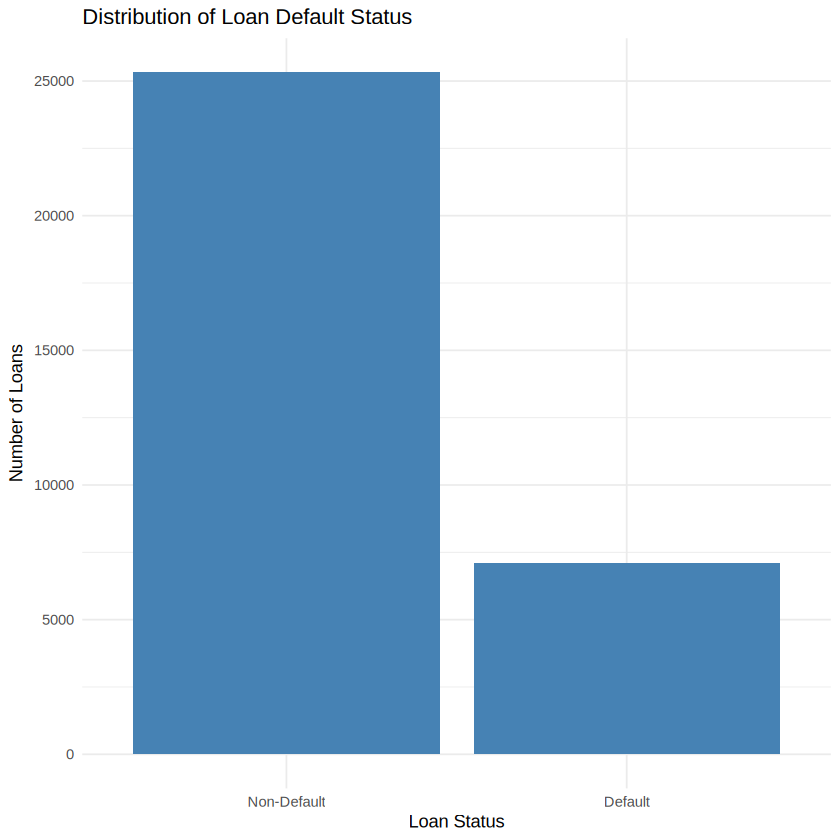

In [ ]:
# Counts
table(loan_clean$loan_status)

# Percentages
round(prop.table(table(loan_clean$loan_status)) * 100, 2)

# Plot
ggplot(loan_clean, aes(x = loan_status)) +
  geom_bar(fill = "steelblue") +
  labs(
    title = "Distribution of Loan Default Status",
    x = "Loan Status",
    y = "Number of Loans"
  ) +
  scale_x_discrete(
    labels = c("0" = "Non-Default", "1" = "Default")
  ) +
  theme_minimal()

##Default Rate by Loan Grade

# A tibble: 7 × 4
  loan_grade Total_Loans Defaults Default_Rate
  <fct>            <int>    <int>        <dbl>
1 A                10702     1066         9.96
2 B                10384     1695        16.3 
3 C                 6436     1336        20.8 
4 D                 3619     2137        59.0 
5 E                  963      621        64.5 
6 F                  241      170        70.5 
7 G                   64       63        98.4 


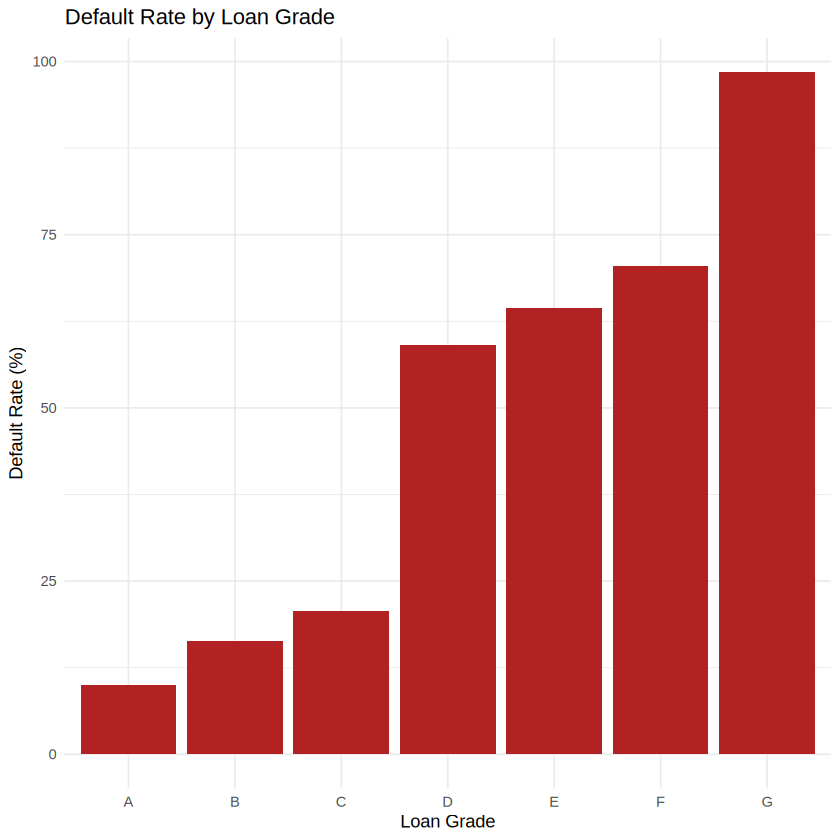

In [ ]:
grade_default <- loan_clean %>%
  group_by(loan_grade) %>%
  summarise(
    Total_Loans = n(),
    Defaults = sum(loan_status == "1", na.rm = TRUE),
    Default_Rate = mean(loan_status == "1", na.rm = TRUE) * 100,
    .groups = "drop"
  )

print(grade_default)

ggplot(grade_default, aes(x = loan_grade, y = Default_Rate)) +
  geom_col(fill = "firebrick") +
  labs(
    title = "Default Rate by Loan Grade",
    x = "Loan Grade",
    y = "Default Rate (%)"
  ) +
  theme_minimal()

##Income Distribution by Loan Default Status

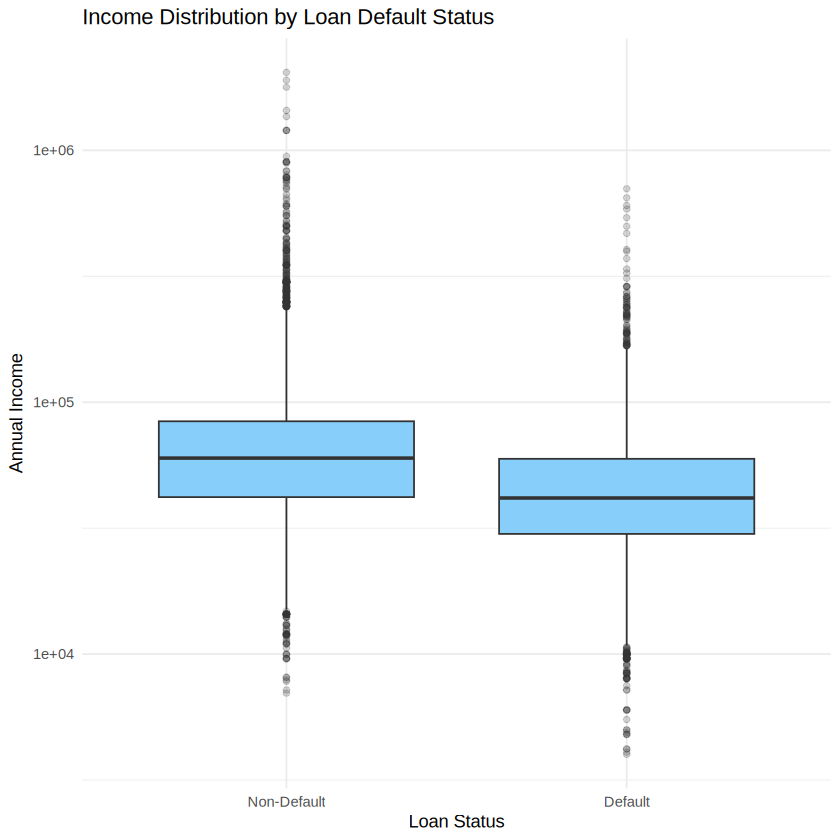

In [ ]:
ggplot(loan_clean, aes(x = loan_status, y = person_income)) +
  geom_boxplot(fill = "lightskyblue", outlier.alpha = 0.2) +
  labs(
    title = "Income Distribution by Loan Default Status",
    x = "Loan Status",
    y = "Annual Income"
  ) +
  scale_x_discrete(
    labels = c("0" = "Non-Default", "1" = "Default")
  ) +
  scale_y_log10() +
  theme_minimal()

##Loan Amount Distribution by Default Status

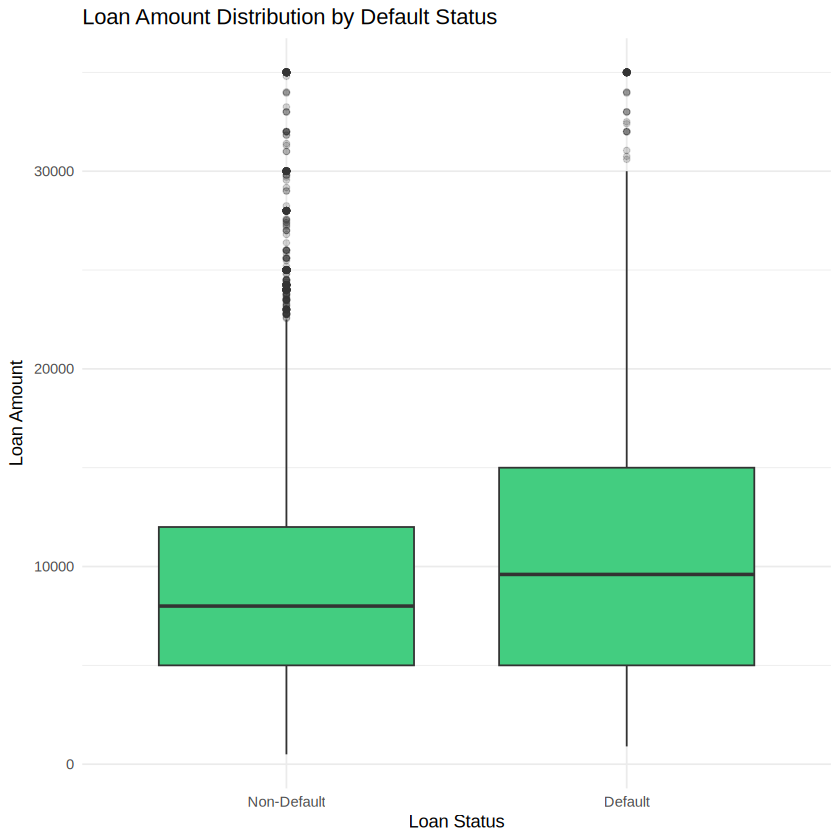

In [ ]:
ggplot(loan_clean, aes(x = loan_status, y = loan_amnt)) +
  geom_boxplot(fill = "seagreen3", outlier.alpha = 0.2) +
  labs(
    title = "Loan Amount Distribution by Default Status",
    x = "Loan Status",
    y = "Loan Amount"
  ) +
  scale_x_discrete(
    labels = c("0" = "Non-Default", "1" = "Default")
  ) +
  theme_minimal()

##Default Rate by Loan Purpose

# A tibble: 6 × 4
  loan_intent       Total_Loans Defaults Default_Rate
  <fct>                   <int>    <int>        <dbl>
1 DEBTCONSOLIDATION        5189     1488         28.7
2 EDUCATION                6409     1106         17.3
3 HOMEIMPROVEMENT          3594      940         26.2
4 MEDICAL                  6042     1617         26.8
5 PERSONAL                 5496     1093         19.9
6 VENTURE                  5679      844         14.9


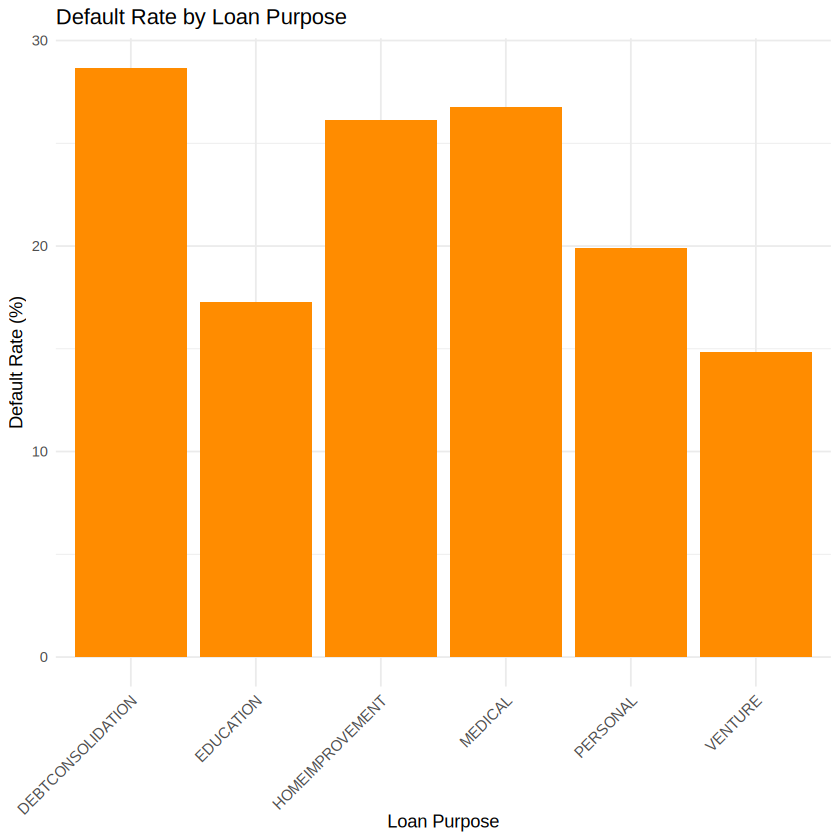

In [ ]:


purpose_default <- loan_clean %>%
  group_by(loan_intent) %>%
  summarise(
    Total_Loans = n(),
    Defaults = sum(loan_status == "1", na.rm = TRUE),
    Default_Rate = mean(loan_status == "1", na.rm = TRUE) * 100,
    .groups = "drop"
  )

print(purpose_default)

ggplot(purpose_default, aes(x = loan_intent, y = Default_Rate)) +
  geom_col(fill = "darkorange") +
  labs(
    title = "Default Rate by Loan Purpose",
    x = "Loan Purpose",
    y = "Default Rate (%)"
  ) +
  theme_minimal() +
  theme(axis.text.x = element_text(angle = 45, hjust = 1))

##Interest Rate Distribution by Default Status

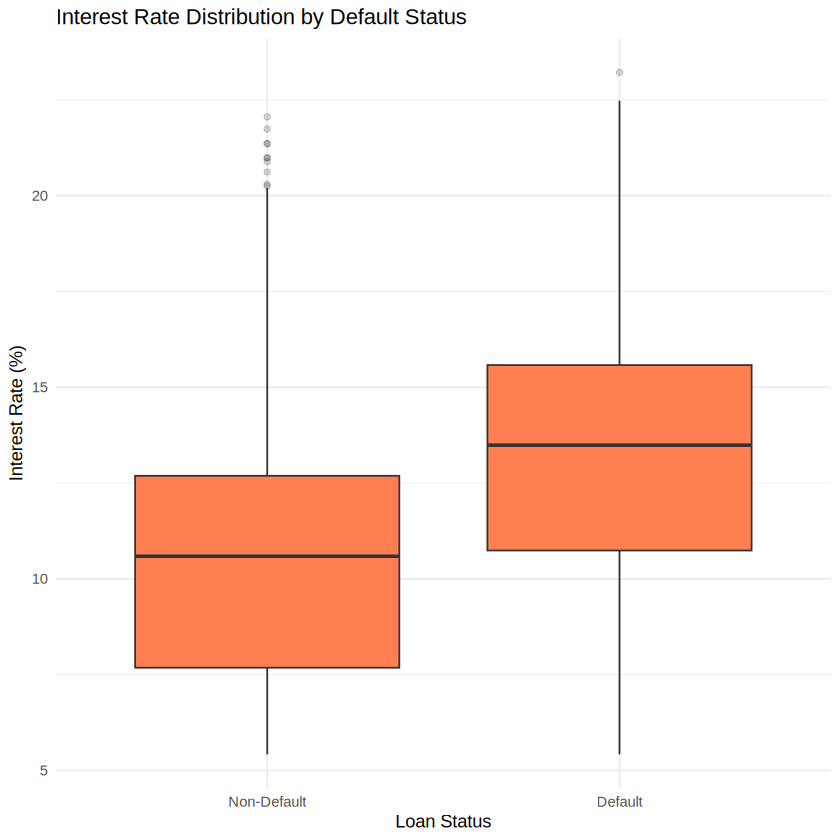

In [ ]:
ggplot(loan_clean, aes(x = loan_status, y = loan_int_rate)) +
  geom_boxplot(fill = "coral", na.rm = TRUE, outlier.alpha = 0.2) +
  labs(
    title = "Interest Rate Distribution by Default Status",
    x = "Loan Status",
    y = "Interest Rate (%)"
  ) +
  scale_x_discrete(
    labels = c("0" = "Non-Default", "1" = "Default")
  ) +
  theme_minimal()

##Loan-to-Income Ratio by Default Status

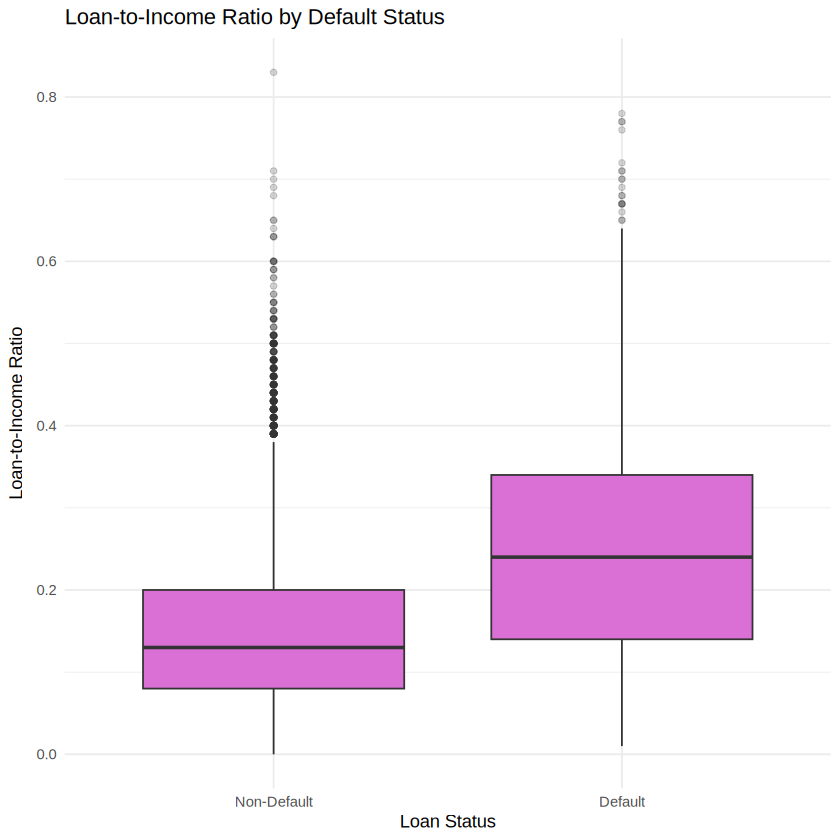

In [ ]:
ggplot(loan_clean, aes(x = loan_status, y = loan_percent_income)) +
  geom_boxplot(fill = "orchid", na.rm = TRUE, outlier.alpha = 0.2) +
  labs(
    title = "Loan-to-Income Ratio by Default Status",
    x = "Loan Status",
    y = "Loan-to-Income Ratio"
  ) +
  scale_x_discrete(
    labels = c("0" = "Non-Default", "1" = "Default")
  ) +
  theme_minimal()

##Previous Default History vs Current Loan Default

# A tibble: 4 × 3
  cb_person_default_on_file loan_status Count
  <fct>                     <fct>       <int>
1 N                         0           21761
2 N                         1            4919
3 Y                         0            3560
4 Y                         1            2169


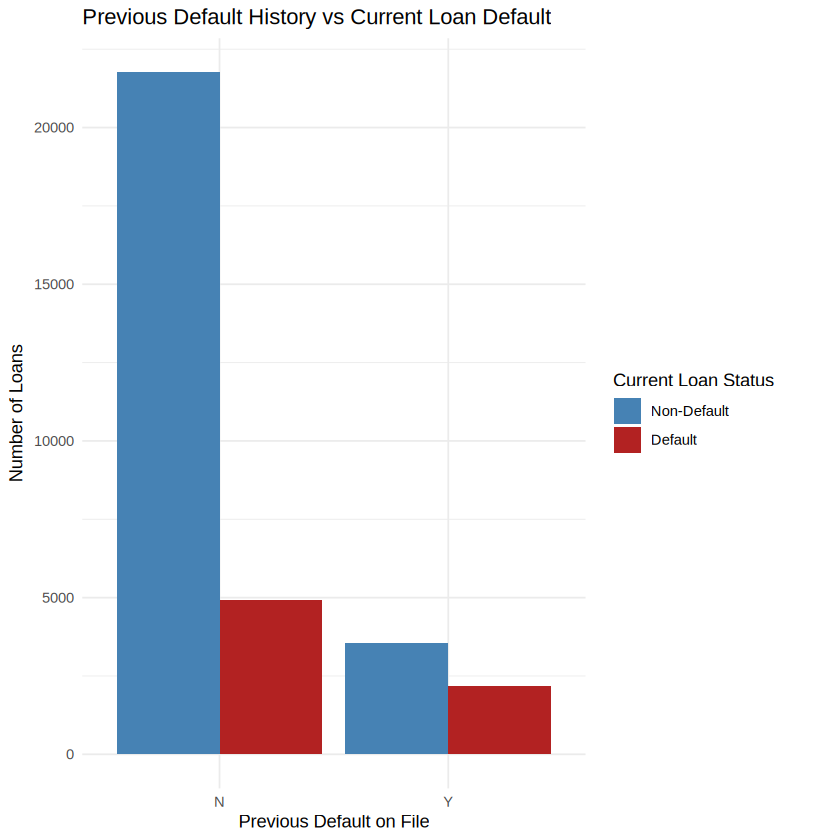

In [ ]:
default_history <- loan_clean %>%
  group_by(cb_person_default_on_file, loan_status) %>%
  summarise(Count = n(), .groups = "drop")

print(default_history)

ggplot(
  default_history,
  aes(
    x = cb_person_default_on_file,
    y = Count,
    fill = loan_status
  )
) +
  geom_col(position = "dodge") +
  labs(
    title = "Previous Default History vs Current Loan Default",
    x = "Previous Default on File",
    y = "Number of Loans",
    fill = "Current Loan Status"
  ) +
  scale_fill_manual(
    values = c("0" = "steelblue", "1" = "firebrick"),
    labels = c("0" = "Non-Default", "1" = "Default")
  ) +
  theme_minimal()

##Default Rate by Home Ownership

# A tibble: 4 × 4
  person_home_ownership Total_Loans Defaults Default_Rate
  <fct>                       <int>    <int>        <dbl>
1 MORTGAGE                    13366     1687        12.6 
2 OTHER                         106       33        31.1 
3 OWN                          2563      192         7.49
4 RENT                        16374     5176        31.6 


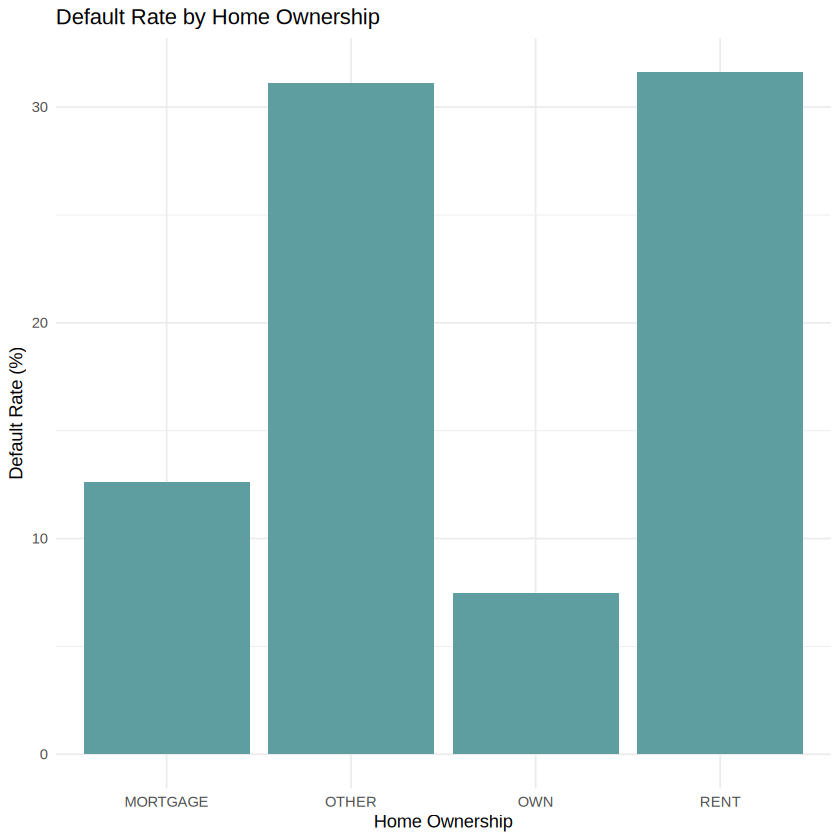

In [ ]:
home_default <- loan_clean %>%
  group_by(person_home_ownership) %>%
  summarise(
    Total_Loans = n(),
    Defaults = sum(loan_status == "1", na.rm = TRUE),
    Default_Rate = mean(loan_status == "1", na.rm = TRUE) * 100,
    .groups = "drop"
  )

print(home_default)

ggplot(home_default, aes(x = person_home_ownership, y = Default_Rate)) +
  geom_col(fill = "cadetblue") +
  labs(
    title = "Default Rate by Home Ownership",
    x = "Home Ownership",
    y = "Default Rate (%)"
  ) +
  theme_minimal()

##Default Rate by Employment Length

# A tibble: 4 × 4
  Employment_Group Total_Loans Defaults Default_Rate
  <fct>                  <int>    <int>        <dbl>
1 0-2 Years              10814     2933         27.1
2 3-5 Years               9229     1851         20.1
3 6-10 Years              8564     1550         18.1
4 10+ Years               2915      473         16.2


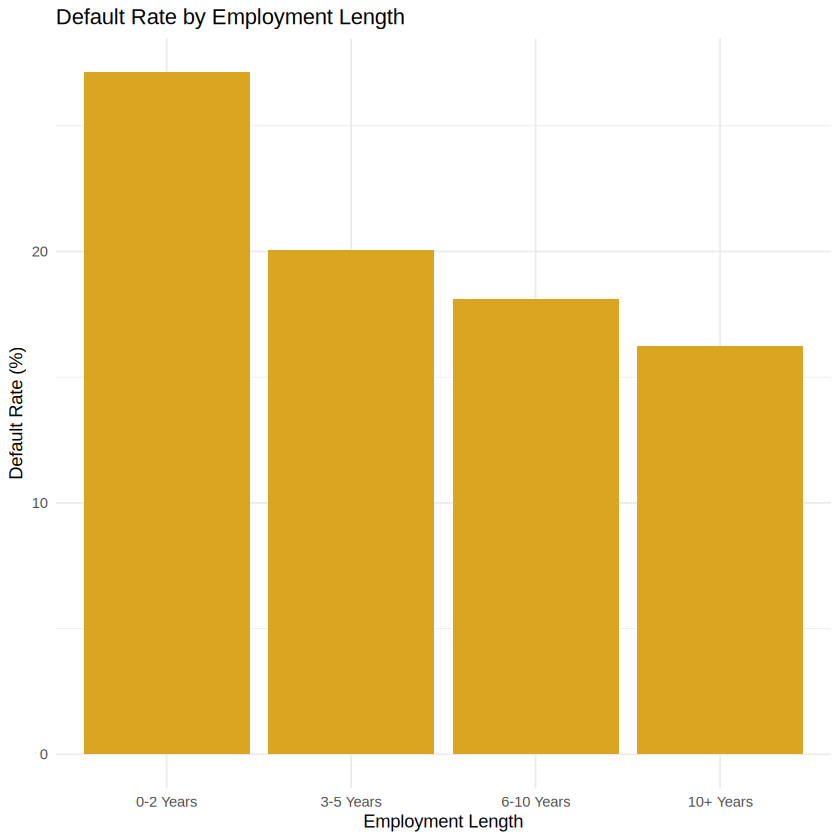

In [ ]:
emp_default <- loan_clean %>%
  filter(!is.na(person_emp_length)) %>%
  mutate(
    Employment_Group = cut(
      person_emp_length,
      breaks = c(-1, 2, 5, 10, Inf),
      labels = c("0-2 Years", "3-5 Years", "6-10 Years", "10+ Years")
    )
  ) %>%
  group_by(Employment_Group) %>%
  summarise(
    Total_Loans = n(),
    Defaults = sum(loan_status == "1", na.rm = TRUE),
    Default_Rate = mean(loan_status == "1", na.rm = TRUE) * 100,
    .groups = "drop"
  )

print(emp_default)

ggplot(emp_default, aes(x = Employment_Group, y = Default_Rate)) +
  geom_col(fill = "goldenrod") +
  labs(
    title = "Default Rate by Employment Length",
    x = "Employment Length",
    y = "Default Rate (%)"
  ) +
  theme_minimal()

##Age Distribution by Loan Default Status

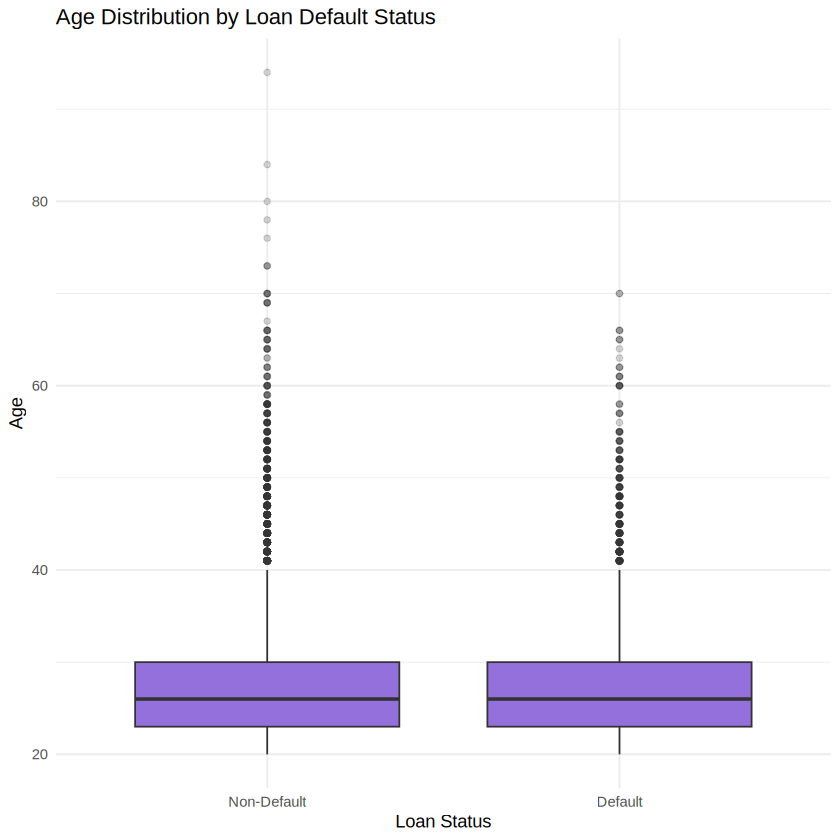

In [ ]:
ggplot(loan_clean, aes(x = loan_status, y = person_age)) +
  geom_boxplot(fill = "mediumpurple", outlier.alpha = 0.2) +
  labs(
    title = "Age Distribution by Loan Default Status",
    x = "Loan Status",
    y = "Age"
  ) +
  scale_x_discrete(
    labels = c("0" = "Non-Default", "1" = "Default")
  ) +
  theme_minimal()

##Correlation Matrix of Numerical Variables

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length
person_age,1.000,0.140,0.172,0.052,0.011,-0.041,0.878
person_income,0.140,1.000,0.154,0.317,-0.001,-0.295,0.123
person_emp_length,0.172,0.154,1.000,0.111,-0.058,-0.058,0.150
loan_amnt,0.052,0.317,0.111,1.000,0.147,0.573,0.042
loan_int_rate,0.011,-0.001,-0.058,0.147,1.000,0.120,0.016
loan_percent_income,-0.041,-0.295,-0.058,0.573,0.120,1.000,-0.031
cb_person_cred_hist_length,0.878,0.123,0.150,0.042,0.016,-0.031,1.000


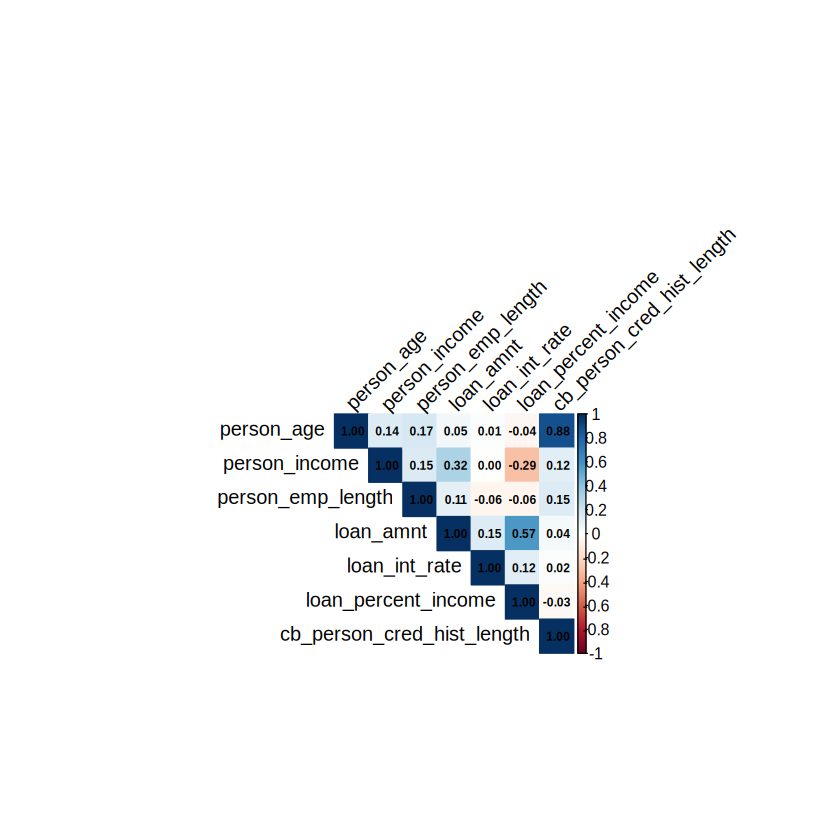

In [ ]:
numeric_data <- loan_clean %>%
  select(
    person_age,
    person_income,
    person_emp_length,
    loan_amnt,
    loan_int_rate,
    loan_percent_income,
    cb_person_cred_hist_length
  )

cor_matrix <- cor(
  numeric_data,
  use = "pairwise.complete.obs",
  method = "pearson"
)

round(cor_matrix, 3)

corrplot(
  cor_matrix,
  method = "color",
  type = "upper",
  addCoef.col = "black",
  tl.col = "black",
  tl.srt = 45,
  number.cex = 0.6
)

##Selected Correlations Among Numerical Variables

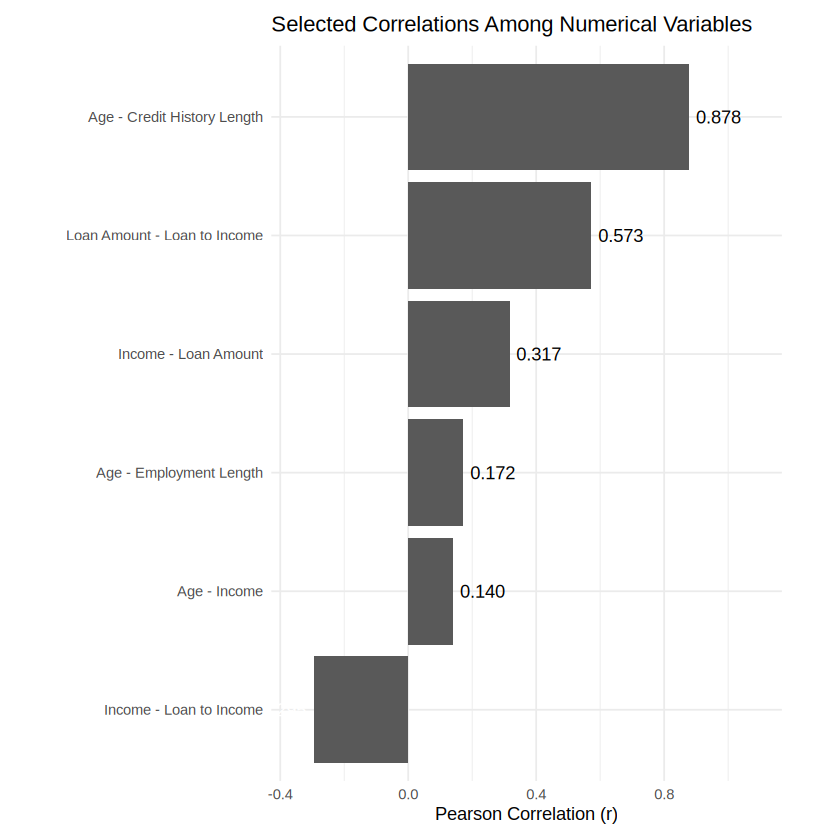

In [ ]:
ggplot(
  correlations,
  aes(x = Relationship, y = Correlation)
) +
  geom_col() +
  geom_text(
    aes(
      label = sprintf("%.3f", Correlation),
      hjust = ifelse(Correlation < 0, 1.15, -0.15),
      color = Correlation < 0
    )
  ) +
  scale_color_manual(
    values = c("TRUE" = "white", "FALSE" = "black"),
    guide = "none"
  ) +
  coord_flip(clip = "off") +
  scale_y_continuous(
    limits = c(-0.4, 1.0),
    expand = expansion(mult = c(0.02, 0.12))
  ) +
  labs(
    title = "Selected Correlations Among Numerical Variables",
    x = NULL,
    y = "Pearson Correlation (r)"
  ) +
  theme_minimal() +
  theme(plot.margin = margin(10, 35, 10, 10))

##**Section 3: Statistical analysis and data preparation**

##Handle Missing Values — Preliminary Median Imputation

In [ ]:
# ============================================================
# STEP 6: HANDLE MISSING VALUES
# ============================================================

# Create a separate dataset for missing-value treatment
loan_imputed <- loan_clean

# Check missing values before treatment
cat("Missing values before treatment:\n")
print(colSums(is.na(loan_imputed)))

# 1. Fill missing employment length using the median
employment_median <- median(
  loan_imputed$person_emp_length,
  na.rm = TRUE
)

loan_imputed$person_emp_length[
  is.na(loan_imputed$person_emp_length)
] <- employment_median

# 2. Fill missing interest rate using the median
interest_rate_median <- median(
  loan_imputed$loan_int_rate,
  na.rm = TRUE
)

loan_imputed$loan_int_rate[
  is.na(loan_imputed$loan_int_rate)
] <- interest_rate_median

# Check missing values after treatment
cat("\nMissing values after treatment:\n")
print(colSums(is.na(loan_imputed)))

# Confirm dataset dimensions
cat("\nDataset dimensions after imputation:\n")
print(dim(loan_imputed))

# Display the imputation values
cat("\nMedian employment length used:",
    employment_median, "\n")

cat("Median interest rate used:",
    interest_rate_median, "\n")

Missing values before treatment:
                person_age              person_income 
                         0                          0 
     person_home_ownership          person_emp_length 
                         0                        887 
               loan_intent                 loan_grade 
                         0                          0 
                 loan_amnt              loan_int_rate 
                         0                       3094 
               loan_status        loan_percent_income 
                         0                          0 
 cb_person_default_on_file cb_person_cred_hist_length 
                         0                          0 

Missing values after treatment:
                person_age              person_income 
                         0                          0 
     person_home_ownership          person_emp_length 
                         0                          0 
               loan_intent                 loan_grade 

In [ ]:
# Confirm no missing values remain
stopifnot(sum(is.na(loan_imputed)) == 0)

# Confirm duplicate rows have not been introduced
cat("Duplicate rows:",
    sum(duplicated(loan_imputed)), "\n")

# Final structure
str(loan_imputed)

# Final summary
summary(loan_imputed)

cat("\nMissing-value treatment completed successfully.\n")

Duplicate rows: 0 
'data.frame':	32409 obs. of  12 variables:
 $ person_age                : int  21 25 23 24 21 26 24 24 21 22 ...
 $ person_income             : int  9600 9600 65500 54400 9900 77100 78956 83000 10000 85000 ...
 $ person_home_ownership     : Factor w/ 4 levels "MORTGAGE","OTHER",..: 3 1 4 4 3 4 4 4 3 4 ...
 $ person_emp_length         : num  5 1 4 8 2 8 5 8 6 6 ...
 $ loan_intent               : Factor w/ 6 levels "DEBTCONSOLIDATION",..: 2 4 4 4 6 2 4 5 6 6 ...
 $ loan_grade                : Factor w/ 7 levels "A","B","C","D",..: 2 3 3 3 1 2 2 1 4 2 ...
 $ loan_amnt                 : int  1000 5500 35000 35000 2500 35000 35000 35000 1600 35000 ...
 $ loan_int_rate             : num  11.14 12.87 15.23 14.27 7.14 ...
 $ loan_status               : Factor w/ 2 levels "0","1": 1 2 2 2 2 2 2 2 2 2 ...
 $ loan_percent_income       : num  0.1 0.57 0.53 0.55 0.25 0.45 0.44 0.42 0.16 0.41 ...
 $ cb_person_default_on_file : Factor w/ 2 levels "N","Y": 1 1 1 2 1 1 1 1 1 1 ...
 $

   person_age    person_income     person_home_ownership person_emp_length
 Min.   :20.00   Min.   :   4000   MORTGAGE:13366        Min.   : 0.000   
 1st Qu.:23.00   1st Qu.:  38500   OTHER   :  106        1st Qu.: 2.000   
 Median :26.00   Median :  55000   OWN     : 2563        Median : 4.000   
 Mean   :27.73   Mean   :  65894   RENT    :16374        Mean   : 4.761   
 3rd Qu.:30.00   3rd Qu.:  79200                         3rd Qu.: 7.000   
 Max.   :94.00   Max.   :2039784                         Max.   :41.000   
                                                                          
            loan_intent   loan_grade   loan_amnt     loan_int_rate  
 DEBTCONSOLIDATION:5189   A:10702    Min.   :  500   Min.   : 5.42  
 EDUCATION        :6409   B:10384    1st Qu.: 5000   1st Qu.: 8.49  
 HOMEIMPROVEMENT  :3594   C: 6436    Median : 8000   Median :10.99  
 MEDICAL          :6042   D: 3619    Mean   : 9592   Mean   :11.01  
 PERSONAL         :5496   E:  963    3rd Qu.:12250   3r


Missing-value treatment completed successfully.


##Statistical Analysis — Chi-Square Tests of Association

In [ ]:
# ============================================================
# STEP 7: STATISTICAL ANALYSIS
# Chi-square tests of association
# ============================================================

# Variables to test against loan default
categorical_variables <- c(
  "loan_grade",
  "loan_intent",
  "person_home_ownership",
  "cb_person_default_on_file"
)

# Store results
chi_results <- data.frame(
  Variable = character(),
  Chi_Square = numeric(),
  Degrees_of_Freedom = integer(),
  P_Value = numeric(),
  Conclusion = character(),
  stringsAsFactors = FALSE
)

# Run each Chi-square test
for (variable in categorical_variables) {

  contingency_table <- table(
    loan_imputed[[variable]],
    loan_imputed$loan_status
  )

  test_result <- chisq.test(contingency_table)

  conclusion <- if (test_result$p.value < 0.05) {
    "Statistically significant association"
  } else {
    "No statistically significant association"
  }

  chi_results <- rbind(
    chi_results,
    data.frame(
      Variable = variable,
      Chi_Square = unname(test_result$statistic),
      Degrees_of_Freedom = unname(test_result$parameter),
      P_Value = test_result$p.value,
      Conclusion = conclusion
    )
  )
}

# Display results
chi_results$Chi_Square <- round(chi_results$Chi_Square, 3)
chi_results$P_Value <- signif(chi_results$P_Value, 4)

print(chi_results, row.names = FALSE)

                  Variable Chi_Square Degrees_of_Freedom    P_Value
                loan_grade   5584.784                  6  0.000e+00
               loan_intent    519.625                  5 4.632e-110
     person_home_ownership   1893.770                  3  0.000e+00
 cb_person_default_on_file   1040.119                  1 3.419e-228
                            Conclusion
 Statistically significant association
 Statistically significant association
 Statistically significant association
 Statistically significant association


##Train-Test Split — 80:20 Stratified Sampling

In [ ]:
# ============================================================
# STEP 8: TRAIN-TEST SPLIT
# ============================================================

# Install caret if it is not already installed
if (!requireNamespace("caret", quietly = TRUE)) {
  install.packages("caret", repos = "https://cloud.r-project.org")
}

library(caret)

# Use the cleaned data before imputation to avoid leakage
model_data <- loan_clean

# Ensure target has the correct class order
model_data$loan_status <- factor(
  model_data$loan_status,
  levels = c("0", "1")
)

# Reproducible 80:20 stratified split
set.seed(123)

train_index <- createDataPartition(
  model_data$loan_status,
  p = 0.80,
  list = FALSE
)

train_data <- model_data[train_index, ]
test_data  <- model_data[-train_index, ]

# Verify split
cat("Training rows:", nrow(train_data), "\n")
cat("Testing rows:", nrow(test_data), "\n")

cat("\nTraining target distribution:\n")
print(round(prop.table(table(train_data$loan_status)) * 100, 2))

cat("\nTesting target distribution:\n")
print(round(prop.table(table(test_data$loan_status)) * 100, 2))

cat("\nTrain/test split completed.\n")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘listenv’, ‘parallelly’, ‘future’, ‘globals’, ‘shape’, ‘future.apply’, ‘numDeriv’, ‘progressr’, ‘SQUAREM’, ‘diagram’, ‘lava’, ‘prodlim’, ‘proxy’, ‘iterators’, ‘clock’, ‘gower’, ‘hardhat’, ‘ipred’, ‘sparsevctrs’, ‘timeDate’, ‘e1071’, ‘foreach’, ‘ModelMetrics’, ‘plyr’, ‘pROC’, ‘recipes’, ‘reshape2’


Loading required package: lattice



Training rows: 25928 
Testing rows: 6481 

Training target distribution:

    0     1 
78.13 21.87 

Testing target distribution:

    0     1 
78.14 21.86 

Train/test split completed.


##**Section 4: Machine learning models**

##Prepare Data and Train Logistic Regression

In [ ]:
# ============================================================
# STEP 9: PREPARE DATA AND TRAIN LOGISTIC REGRESSION
# ============================================================

# 1. Calculate imputation values from training data only
employment_median <- median(
  train_data$person_emp_length,
  na.rm = TRUE
)

interest_median <- median(
  train_data$loan_int_rate,
  na.rm = TRUE
)

# 2. Apply the training medians to both datasets
train_data$person_emp_length[
  is.na(train_data$person_emp_length)
] <- employment_median

test_data$person_emp_length[
  is.na(test_data$person_emp_length)
] <- employment_median

train_data$loan_int_rate[
  is.na(train_data$loan_int_rate)
] <- interest_median

test_data$loan_int_rate[
  is.na(test_data$loan_int_rate)
] <- interest_median

# 3. Remove the target from the predictors automatically


# 4. Train Logistic Regression
logistic_model <- glm(
  loan_status ~ .,
  data = train_data,
  family = binomial(link = "logit")
)

# 5. Display model results
summary(logistic_model)

cat("\nLogistic Regression training completed.\n")
cat("Training rows:", nrow(train_data), "\n")
cat("Testing rows:", nrow(test_data), "\n")

cat(
  "Remaining missing values in training data:",
  sum(is.na(train_data)), "\n"
)

cat(
  "Remaining missing values in testing data:",
  sum(is.na(test_data)), "\n"
)


Call:
glm(formula = loan_status ~ ., family = binomial(link = "logit"), 
    data = train_data)

Coefficients:
                             Estimate Std. Error z value Pr(>|z|)    
(Intercept)                -4.099e+00  1.945e-01 -21.072  < 2e-16 ***
person_age                 -4.163e-03  6.561e-03  -0.635  0.52575    
person_income               1.640e-06  5.962e-07   2.751  0.00595 ** 
person_home_ownershipOTHER  7.714e-01  3.194e-01   2.415  0.01573 *  
person_home_ownershipOWN   -1.787e+00  1.141e-01 -15.669  < 2e-16 ***
person_home_ownershipRENT   8.091e-01  4.479e-02  18.064  < 2e-16 ***
person_emp_length          -1.432e-02  5.376e-03  -2.663  0.00774 ** 
loan_intentEDUCATION       -8.743e-01  6.412e-02 -13.636  < 2e-16 ***
loan_intentHOMEIMPROVEMENT  4.334e-02  7.093e-02   0.611  0.54119    
loan_intentMEDICAL         -1.857e-01  6.042e-02  -3.074  0.00212 ** 
loan_intentPERSONAL        -6.458e-01  6.556e-02  -9.850  < 2e-16 ***
loan_intentVENTURE         -1.107e+00  6.896e-02


Logistic Regression training completed.
Training rows: 25928 
Testing rows: 6481 
Remaining missing values in training data: 0 
Remaining missing values in testing data: 0 


##Evaluate Logistic Regression on Test Data


--- Logistic Regression Test Metrics ---
Accuracy : 0.8619 
Precision: 0.7554 
Recall   : 0.5448 
F1-score : 0.633 


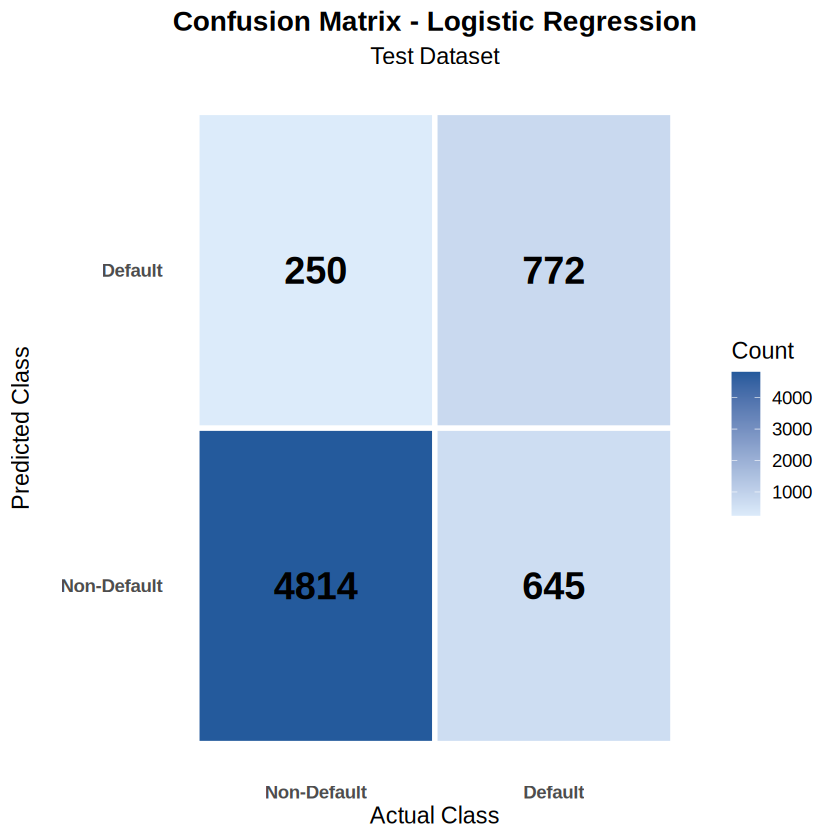

In [ ]:

# Step 9: Evaluate Logistic Regression on Test Data

# Predict probability of default (loan_status = 1)
logistic_prob <- predict(
  logistic_model,
  newdata = test_data,
  type = "response"
)

# Convert probabilities into class predictions using 0.5 threshold
logistic_pred <- ifelse(logistic_prob >= 0.5, "1", "0")

# Set the correct factor levels
logistic_pred <- factor(logistic_pred, levels = c("0", "1"))
actual_status <- factor(test_data$loan_status, levels = c("0", "1"))


# Visual Confusion Matrix - Logistic Regression

library(ggplot2)

logistic_cm_df <- as.data.frame(conf_matrix$table)
colnames(logistic_cm_df) <- c("Predicted", "Actual", "Count")

ggplot(logistic_cm_df, aes(x = Actual, y = Predicted, fill = Count)) +
  geom_tile(color = "white", linewidth = 1.5) +
  geom_text(aes(label = Count), size = 8, fontface = "bold") +
  scale_fill_gradient(low = "#DCEBFA", high = "#245A9C") +
  scale_x_discrete(labels = c("0" = "Non-Default", "1" = "Default")) +
  scale_y_discrete(labels = c("0" = "Non-Default", "1" = "Default")) +
  labs(
    title = "Confusion Matrix - Logistic Regression",
    subtitle = "Test Dataset",
    x = "Actual Class",
    y = "Predicted Class",
    fill = "Count"
  ) +
  theme_minimal(base_size = 14) +
  theme(
    plot.title = element_text(face = "bold", hjust = 0.5),
    plot.subtitle = element_text(hjust = 0.5),
    axis.text = element_text(face = "bold"),
    panel.grid = element_blank()
  )


# Calculate evaluation metrics
cm <- conf_matrix$table

true_negative  <- cm["0", "0"]
false_negative <- cm["0", "1"]
false_positive <- cm["1", "0"]
true_positive  <- cm["1", "1"]

accuracy <- (true_positive + true_negative) / sum(cm)
precision <- ifelse(
  true_positive + false_positive > 0,
  true_positive / (true_positive + false_positive), 0
)
recall <- ifelse(
  true_positive + false_negative > 0,
  true_positive / (true_positive + false_negative), 0
)
f1_score <- ifelse(
  precision + recall > 0,
  2 * precision * recall / (precision + recall), 0
)

cat("\n--- Logistic Regression Test Metrics ---\n")
cat("Accuracy :", round(accuracy, 4), "\n")
cat("Precision:", round(precision, 4), "\n")
cat("Recall   :", round(recall, 4), "\n")
cat("F1-score :", round(f1_score, 4), "\n")


##ROC Curve and AUC — Logistic Regressio

Logistic Regression ROC-AUC: 0.8639 


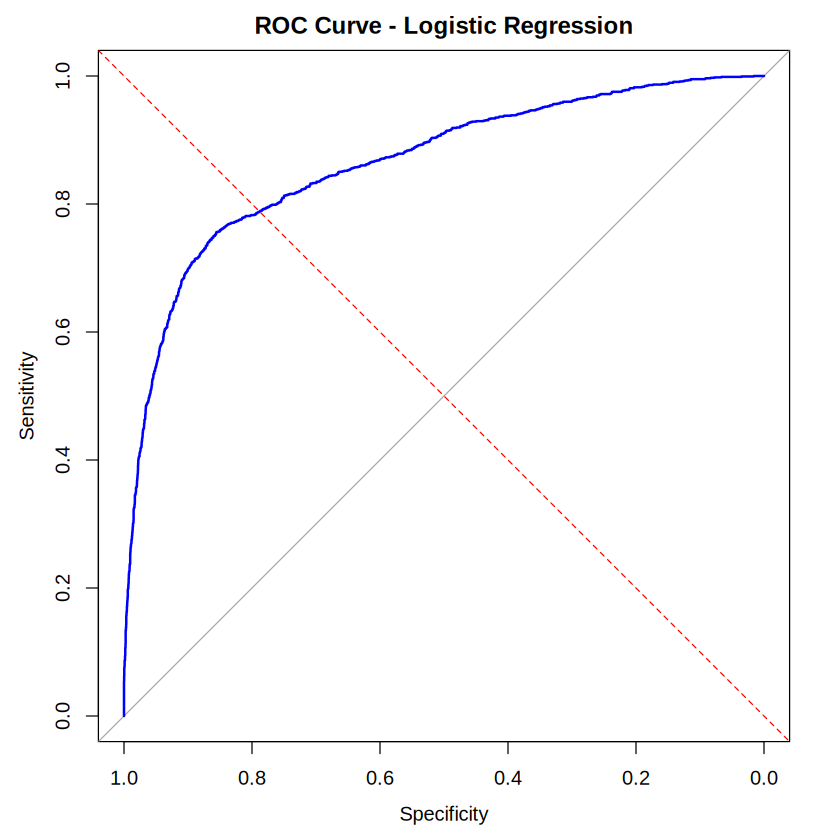

In [ ]:

# Step 10: ROC Curve and AUC



library(pROC)

roc_result <- roc(
  response = actual_status,
  predictor = logistic_prob,
  levels = c("0", "1"),
  direction = "<",
  quiet = TRUE
)

auc_value <- as.numeric(auc(roc_result))

cat("Logistic Regression ROC-AUC:",
    round(auc_value, 4), "\n")

plot(
  roc_result,
  main = "ROC Curve - Logistic Regression",
  col = "blue",
  lwd = 2
)

abline(a = 0, b = 1, lty = 2, col = "red")


##Train Random Forest Model

In [ ]:

# Step 11: Train Random Forest Model


library(randomForest)

set.seed(123)

rf_model <- randomForest(
  loan_status ~ .,
  data = train_data,
  ntree = 300,
  importance = TRUE
)

print(rf_model)

cat("\nRandom Forest training completed.\n")



Call:
 randomForest(formula = loan_status ~ ., data = train_data, ntree = 300,      importance = TRUE) 
               Type of random forest: classification
                     Number of trees: 300
No. of variables tried at each split: 3

        OOB estimate of  error rate: 6.63%
Confusion matrix:
      0    1 class.error
0 20147  110 0.005430222
1  1608 4063 0.283547875

Random Forest training completed.


##Evaluate Random Forest on Test Data


--- Random Forest Test Metrics ---
Accuracy : 0.9375 
Precision: 0.9765 
Recall   : 0.7318 
F1-score : 0.8366 
ROC-AUC  : 0.9384 


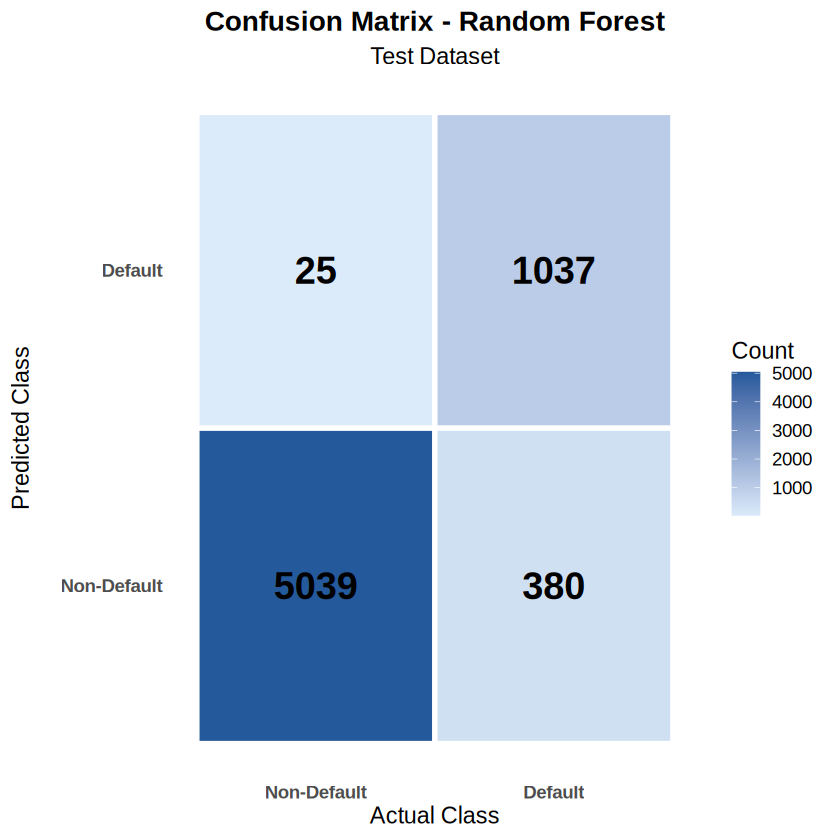

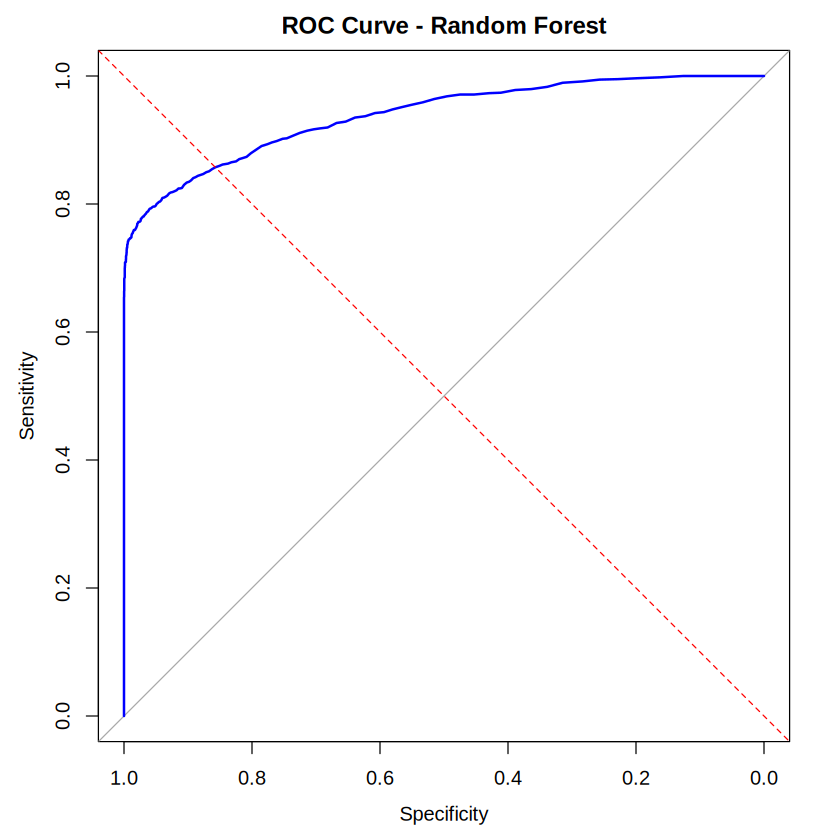

In [ ]:

# Step 12: Random Forest Test Evaluation

rf_prob <- predict(rf_model, newdata = test_data, type = "prob")[, "1"]

rf_pred <- predict(rf_model, newdata = test_data, type = "response")


# Visual Confusion Matrix - Random Forest

rf_cm_df <- as.data.frame(rf_conf_matrix$table)
colnames(rf_cm_df) <- c("Predicted", "Actual", "Count")

ggplot(rf_cm_df, aes(x = Actual, y = Predicted, fill = Count)) +
  geom_tile(color = "white", linewidth = 1.5) +
  geom_text(aes(label = Count), size = 8, fontface = "bold") +
  scale_fill_gradient(low = "#DCEBFA", high = "#245A9C") +
  scale_x_discrete(labels = c("0" = "Non-Default", "1" = "Default")) +
  scale_y_discrete(labels = c("0" = "Non-Default", "1" = "Default")) +
  labs(
    title = "Confusion Matrix - Random Forest",
    subtitle = "Test Dataset",
    x = "Actual Class",
    y = "Predicted Class",
    fill = "Count"
  ) +
  theme_minimal(base_size = 14) +
  theme(
    plot.title = element_text(face = "bold", hjust = 0.5),
    plot.subtitle = element_text(hjust = 0.5),
    axis.text = element_text(face = "bold"),
    panel.grid = element_blank()
  )


rf_cm <- rf_conf_matrix$table

rf_tn <- rf_cm["0", "0"]
rf_fn <- rf_cm["0", "1"]
rf_fp <- rf_cm["1", "0"]
rf_tp <- rf_cm["1", "1"]

rf_accuracy <- (rf_tp + rf_tn) / sum(rf_cm)
rf_precision <- rf_tp / (rf_tp + rf_fp)
rf_recall <- rf_tp / (rf_tp + rf_fn)
rf_f1 <- 2 * rf_precision * rf_recall / (rf_precision + rf_recall)

cat("\n--- Random Forest Test Metrics ---\n")
cat("Accuracy :", round(rf_accuracy, 4), "\n")
cat("Precision:", round(rf_precision, 4), "\n")
cat("Recall   :", round(rf_recall, 4), "\n")
cat("F1-score :", round(rf_f1, 4), "\n")

rf_roc <- roc(
  response = actual_status,
  predictor = rf_prob,
  levels = c("0", "1"),
  direction = "<",
  quiet = TRUE
)

rf_auc <- as.numeric(auc(rf_roc))
cat("ROC-AUC  :", round(rf_auc, 4), "\n")

plot(rf_roc, main = "ROC Curve - Random Forest", col = "blue", lwd = 2)
abline(a = 0, b = 1, lty = 2, col = "red")


##Model Performance Comparison — Logistic Regression vs Random Forest

  Accuracy Precision Recall F1_Score ROC_AUC               Model
1   0.8619    0.7554 0.5448   0.6330  0.8639 Logistic Regression
2   0.9375    0.9765 0.7318   0.8366  0.9384       Random Forest


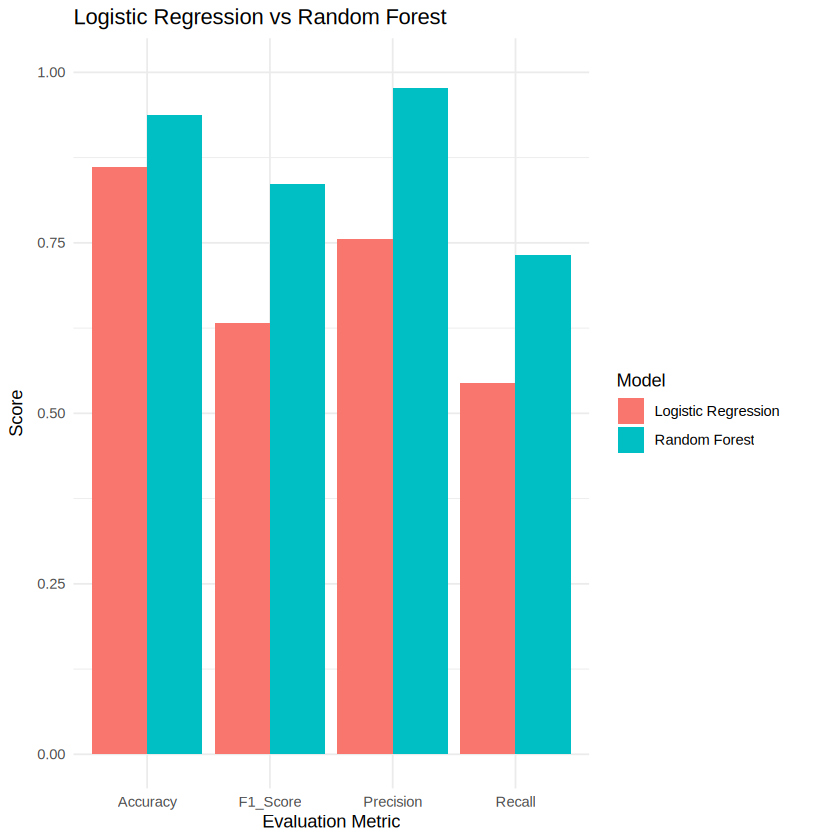

In [ ]:
# Step 13: Model Performance Comparison

model_comparison <- data.frame(
  Model = c("Logistic Regression", "Random Forest"),
  Accuracy = c(accuracy, rf_accuracy),
  Precision = c(precision, rf_precision),
  Recall = c(recall, rf_recall),
  F1_Score = c(f1_score, rf_f1),
  ROC_AUC = c(auc_value, rf_auc)
)

print(round(model_comparison[-1], 4) |>
        cbind(Model = model_comparison$Model))

# Plot comparison
comparison_long <- data.frame(
  Model = rep(model_comparison$Model, each = 4),
  Metric = rep(c("Accuracy", "Precision", "Recall", "F1_Score"), 2),
  Score = c(
    accuracy, precision, recall, f1_score,
    rf_accuracy, rf_precision, rf_recall, rf_f1
  )
)

ggplot(comparison_long, aes(x = Metric, y = Score, fill = Model)) +
  geom_col(position = "dodge") +
  labs(
    title = "Logistic Regression vs Random Forest",
    x = "Evaluation Metric",
    y = "Score"
  ) +
  ylim(0, 1) +
  theme_minimal()

## Feature Importance of Random Forest


                                              Feature Importance
loan_percent_income               loan_percent_income  1924.0951
person_income                           person_income  1280.4665
loan_grade                                 loan_grade  1044.5926
loan_int_rate                           loan_int_rate   957.0813
person_home_ownership           person_home_ownership   944.5979
loan_intent                               loan_intent   747.2400
loan_amnt                                   loan_amnt   613.5121
person_emp_length                   person_emp_length   547.3614
person_age                                 person_age   381.5152
cb_person_cred_hist_length cb_person_cred_hist_length   287.6509
cb_person_default_on_file   cb_person_default_on_file    80.5233


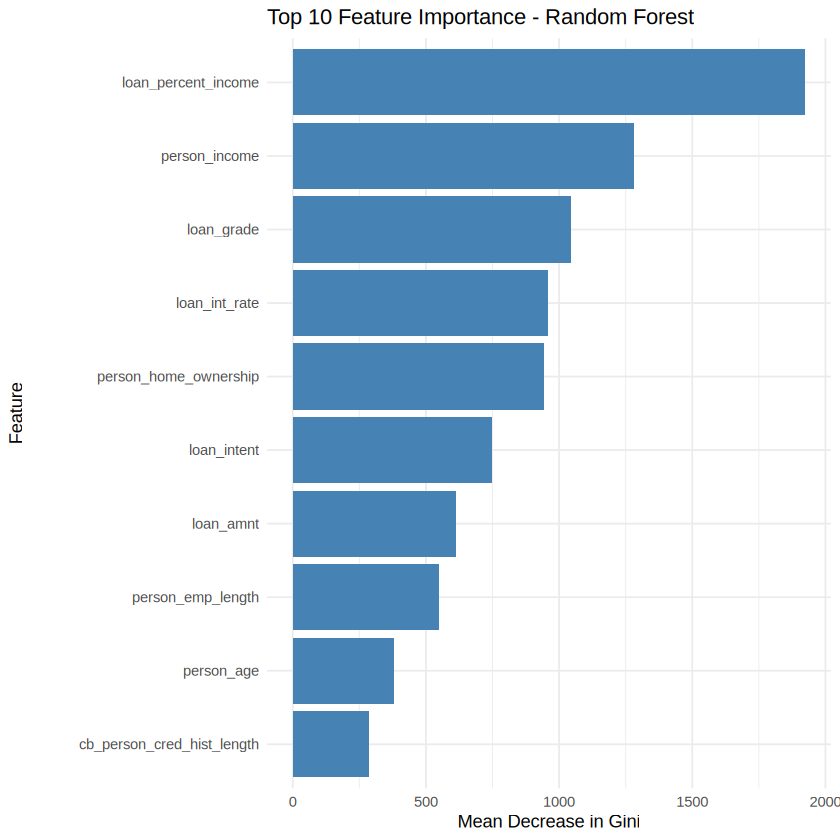

In [ ]:
# Step 14: Identify Important Predictors

importance_values <- importance(rf_model)

importance_df <- data.frame(
  Feature = rownames(importance_values),
  Importance = importance_values[, "MeanDecreaseGini"]
)

importance_df <- importance_df[
  order(importance_df$Importance, decreasing = TRUE),
]

print(importance_df)

# Visualize the top 10 important features
top_features <- head(importance_df, 10)

ggplot(top_features, aes(
  x = reorder(Feature, Importance),
  y = Importance
)) +
  geom_col(fill = "steelblue") +
  coord_flip() +
  labs(
    title = "Top 10 Feature Importance - Random Forest",
    x = "Feature",
    y = "Mean Decrease in Gini"
  ) +
  theme_minimal()

In [ ]:

# Cell 35: Final Model Validation

cat("===== FINAL PROJECT VALIDATION =====\n\n")

# Dataset validation
cat("Training rows:", nrow(train_data), "\n")
cat("Testing rows:", nrow(test_data), "\n")
cat("Missing values in training data:", sum(is.na(train_data)), "\n")
cat("Missing values in testing data:", sum(is.na(test_data)), "\n")

# Check prediction counts
cat("\nTest prediction count:", length(rf_pred), "\n")
cat("Actual test labels:", length(actual_status), "\n")

# Final model metrics
cat("\n===== FINAL RANDOM FOREST RESULTS =====\n")
cat("Accuracy :", round(rf_accuracy * 100, 2), "%\n")
cat("Precision:", round(rf_precision * 100, 2), "%\n")
cat("Recall   :", round(rf_recall * 100, 2), "%\n")
cat("F1-score :", round(rf_f1, 4), "\n")
cat("ROC-AUC  :", round(rf_auc, 4), "\n")

# Validation checks
stopifnot(
  sum(is.na(train_data)) == 0,
  sum(is.na(test_data)) == 0,
  length(rf_pred) == nrow(test_data),
  length(rf_prob) == nrow(test_data)
)

cat("\nAll final validation checks passed.\n")


===== FINAL PROJECT VALIDATION =====

Training rows: 25928 
Testing rows: 6481 
Missing values in training data: 0 
Missing values in testing data: 0 

Test prediction count: 6481 
Actual test labels: 6481 

===== FINAL RANDOM FOREST RESULTS =====
Accuracy : 93.75 %
Precision: 97.65 %
Recall   : 73.18 %
F1-score : 0.8366 
ROC-AUC  : 0.9384 

All final validation checks passed.


  Threshold Accuracy Precision Recall     F1
1      0.50   0.9377    0.9765 0.7325 0.8371
2      0.45   0.9384    0.9661 0.7445 0.8410
3      0.40   0.9364    0.9467 0.7516 0.8379
4      0.35   0.9329    0.9126 0.7664 0.8331
5      0.30   0.9262    0.8654 0.7848 0.8231
6      0.25   0.9114    0.7905 0.8095 0.7999
7      0.20   0.8824    0.6907 0.8370 0.7569


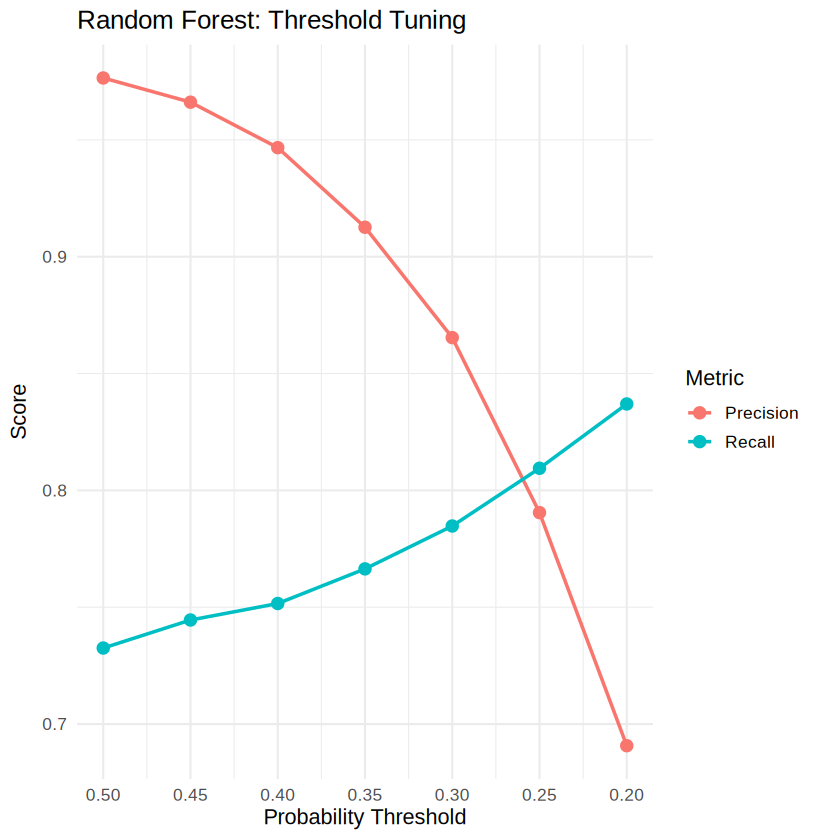

In [ ]:

# Cell 38: Tune Random Forest Classification Threshold

thresholds <- c(0.50, 0.45, 0.40, 0.35, 0.30, 0.25, 0.20)

threshold_results <- data.frame()

for (threshold in thresholds) {

  pred <- factor(
    ifelse(rf_prob >= threshold, "1", "0"),
    levels = c("0", "1")
  )

  cm <- confusionMatrix(
    data = pred,
    reference = actual_status,
    positive = "1"
  )

  threshold_results <- rbind(
    threshold_results,
    data.frame(
      Threshold = threshold,
      Accuracy = unname(cm$overall["Accuracy"]),
      Precision = unname(cm$byClass["Pos Pred Value"]),
      Recall = unname(cm$byClass["Sensitivity"]),
      F1 = unname(cm$byClass["F1"])
    )
  )
}

print(round(threshold_results, 4))

# Visualize recall and precision trade-off
library(ggplot2)

threshold_plot <- rbind(
  data.frame(
    Threshold = threshold_results$Threshold,
    Metric = "Recall",
    Value = threshold_results$Recall
  ),
  data.frame(
    Threshold = threshold_results$Threshold,
    Metric = "Precision",
    Value = threshold_results$Precision
  )
)

ggplot(
  threshold_plot,
  aes(x = Threshold, y = Value, color = Metric)
) +
  geom_line(linewidth = 1) +
  geom_point(size = 3) +
  scale_x_reverse(breaks = thresholds) +
  labs(
    title = "Random Forest: Threshold Tuning",
    x = "Probability Threshold",
    y = "Score",
    color = "Metric"
  ) +
  theme_minimal(base_size = 13)


In [ ]:

# Cell 39: Class-Weighted Random Forest

set.seed(123)

rf_weighted <- randomForest(
  loan_status ~ .,
  data = train_data,
  ntree = 500,
  importance = TRUE,
  classwt = c("0" = 1, "1" = 2)
)

# Default probabilities on the same test set
rf_weighted_prob <- predict(
  rf_weighted,
  newdata = test_data,
  type = "prob"
)[, "1"]

# Evaluate using the same 0.5 threshold
rf_weighted_pred <- factor(
  ifelse(rf_weighted_prob >= 0.5, "1", "0"),
  levels = c("0", "1")
)

weighted_cm <- confusionMatrix(
  data = rf_weighted_pred,
  reference = actual_status,
  positive = "1"
)

print(weighted_cm)

cat("\nClass-Weighted Random Forest Metrics\n")
cat("Accuracy :", round(weighted_cm$overall["Accuracy"], 4), "\n")
cat("Precision:", round(weighted_cm$byClass["Pos Pred Value"], 4), "\n")
cat("Recall   :", round(weighted_cm$byClass["Sensitivity"], 4), "\n")
cat("F1-score :", round(weighted_cm$byClass["F1"], 4), "\n")


Confusion Matrix and Statistics

          Reference
Prediction    0    1
         0 5040  388
         1   24 1029
                                          
               Accuracy : 0.9364          
                 95% CI : (0.9302, 0.9422)
    No Information Rate : 0.7814          
    P-Value [Acc > NIR] : < 2.2e-16       
                                          
                  Kappa : 0.795           
                                          
 Mcnemar's Test P-Value : < 2.2e-16       
                                          
            Sensitivity : 0.7262          
            Specificity : 0.9953          
         Pos Pred Value : 0.9772          
         Neg Pred Value : 0.9285          
             Prevalence : 0.2186          
         Detection Rate : 0.1588          
   Detection Prevalence : 0.1625          
      Balanced Accuracy : 0.8607          
                                          
       'Positive' Class : 1               
                        

In [ ]:

# Cell 40: Check Small Category Counts

cat("\nLoan Grade Counts:\n")
print(table(loan_clean$loan_grade))

cat("\nHome Ownership Counts:\n")
print(table(loan_clean$person_home_ownership))

cat("\nDefault Rates by Loan Grade:\n")
print(round(
  prop.table(
    table(loan_clean$loan_grade, loan_clean$loan_status),
    margin = 1
  )[, "1"] * 100,
  2
))

cat("\nDefault Rates by Home Ownership:\n")
print(round(
  prop.table(
    table(
      loan_clean$person_home_ownership,
      loan_clean$loan_status
    ),
    margin = 1
  )[, "1"] * 100,
  2
))



Loan Grade Counts:

    A     B     C     D     E     F     G 
10702 10384  6436  3619   963   241    64 

Home Ownership Counts:

MORTGAGE    OTHER      OWN     RENT 
   13366      106     2563    16374 

Default Rates by Loan Grade:
    A     B     C     D     E     F     G 
 9.96 16.32 20.76 59.05 64.49 70.54 98.44 

Default Rates by Home Ownership:
MORTGAGE    OTHER      OWN     RENT 
   12.62    31.13     7.49    31.61 


Confusion Matrix and Statistics

          Reference
Prediction    0    1
         0 5004  352
         1   60 1065
                                          
               Accuracy : 0.9364          
                 95% CI : (0.9302, 0.9422)
    No Information Rate : 0.7814          
    P-Value [Acc > NIR] : < 2.2e-16       
                                          
                  Kappa : 0.799           
                                          
 Mcnemar's Test P-Value : < 2.2e-16       
                                          
            Sensitivity : 0.7516          
            Specificity : 0.9882          
         Pos Pred Value : 0.9467          
         Neg Pred Value : 0.9343          
             Prevalence : 0.2186          
         Detection Rate : 0.1643          
   Detection Prevalence : 0.1736          
      Balanced Accuracy : 0.8699          
                                          
       'Positive' Class : 1               
                        

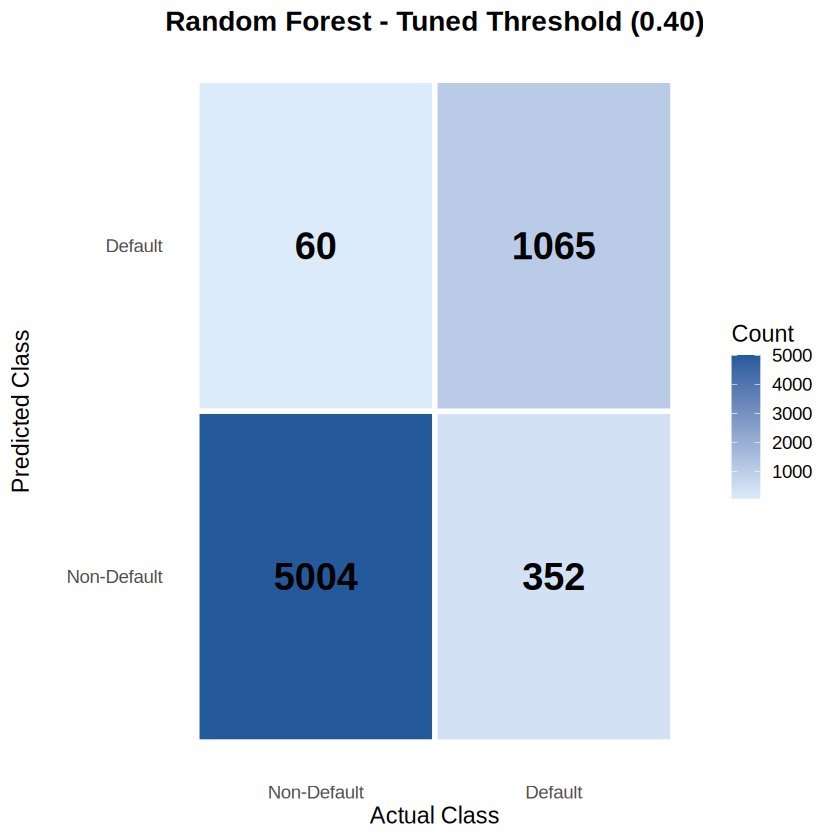

In [ ]:

# Cell 41: Final Random Forest Evaluation at Threshold 0.40

chosen_threshold <- 0.40

rf_tuned_pred <- factor(
  ifelse(rf_prob >= chosen_threshold, "1", "0"),
  levels = c("0", "1")
)

rf_tuned_cm <- confusionMatrix(
  data = rf_tuned_pred,
  reference = actual_status,
  positive = "1"
)

print(rf_tuned_cm)

# Confusion matrix as a visual plot
library(ggplot2)

rf_tuned_df <- as.data.frame(rf_tuned_cm$table)
colnames(rf_tuned_df) <- c("Predicted", "Actual", "Count")

ggplot(rf_tuned_df, aes(x = Actual, y = Predicted, fill = Count)) +
  geom_tile(color = "white", linewidth = 1.5) +
  geom_text(aes(label = Count), size = 8, fontface = "bold") +
  scale_fill_gradient(low = "#DCEBFA", high = "#245A9C") +
  scale_x_discrete(
    labels = c("0" = "Non-Default", "1" = "Default")
  ) +
  scale_y_discrete(
    labels = c("0" = "Non-Default", "1" = "Default")
  ) +
  labs(
    title = "Random Forest - Tuned Threshold (0.40)",
    x = "Actual Class",
    y = "Predicted Class",
    fill = "Count"
  ) +
  theme_minimal(base_size = 14) +
  theme(
    plot.title = element_text(face = "bold", hjust = 0.5),
    panel.grid = element_blank()
  )

cat("\nThreshold:", chosen_threshold, "\n")
cat("Accuracy :", round(rf_tuned_cm$overall["Accuracy"], 4), "\n")
cat("Precision:", round(rf_tuned_cm$byClass["Pos Pred Value"], 4), "\n")
cat("Recall   :", round(rf_tuned_cm$byClass["Sensitivity"], 4), "\n")
cat("F1-score :", round(rf_tuned_cm$byClass["F1"], 4), "\n")


## LIME Explainability for Random Forest

# A tibble: 6 × 13
  model_type    case  label label_prob model_r2 model_intercept model_prediction
  <chr>         <chr> <chr>      <dbl>    <dbl>           <dbl>            <dbl>
1 classificati… 20    1           0.88    0.138           0.460            0.374
2 classificati… 20    1           0.88    0.138           0.460            0.374
3 classificati… 20    1           0.88    0.138           0.460            0.374
4 classificati… 20    1           0.88    0.138           0.460            0.374
5 classificati… 20    1           0.88    0.138           0.460            0.374
6 classificati… 20    1           0.88    0.138           0.460            0.374
# ℹ 6 more variables: feature <chr>, feature_value <dbl>, feature_weight <dbl>,
#   feature_desc <chr>, data <list>, prediction <list>
Applicant index: 2 
Predicted class: 1 
Actual class: 1 


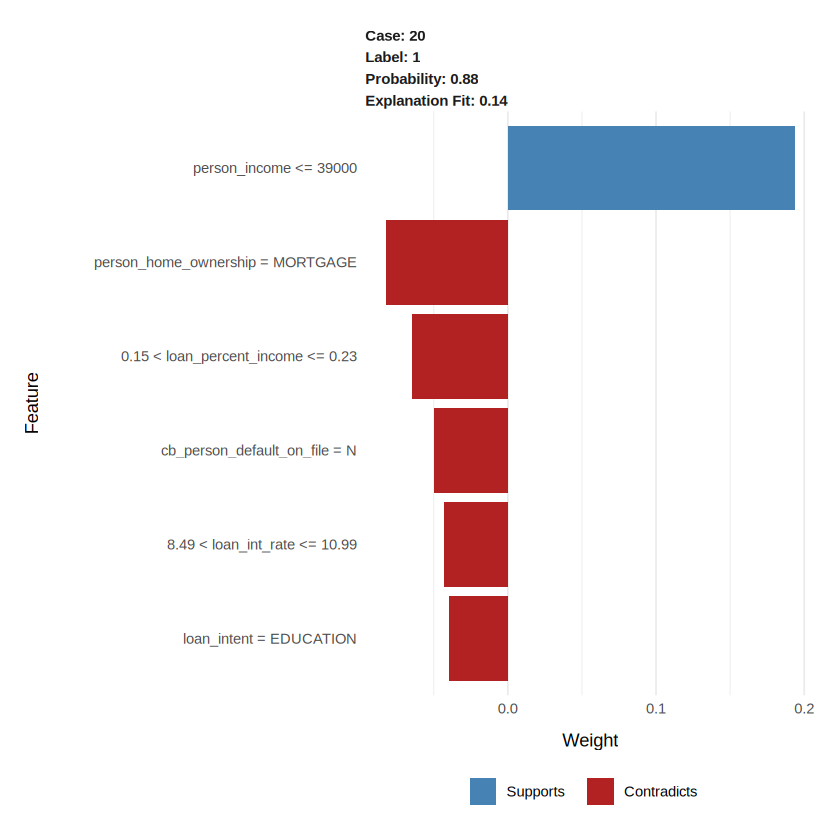

In [ ]:



library(lime)
library(randomForest)
library(ggplot2)

# Register the Random Forest model type for LIME
model_type.randomForest <- function(x, ...) {
  "classification"
}

# Prepare training features (exclude target)
lime_train <- train_data[
  , setdiff(names(train_data), "loan_status"),
  drop = FALSE
]

# Prediction function returning class probabilities
predict_rf_lime <- function(model, newdata) {
  probabilities <- predict(
    model,
    newdata = newdata,
    type = "prob"
  )

  probabilities <- as.data.frame(probabilities)
  names(probabilities) <- as.character(
    as.numeric(names(probabilities))
  )

  probabilities
}

# Create LIME explainer
lime_explainer <- lime(
  x = lime_train,
  model = rf_model,
  bin_continuous = TRUE,
  n_bins = 4,
  quantile_bins = TRUE
)

# Select the first test applicant predicted as default
default_cases <- which(as.character(rf_pred) == "1")

if (length(default_cases) == 0) {
  stop("No applicants predicted as default. Check rf_pred.")
}

case_index <- default_cases[1]

applicant <- test_data[
  case_index,
  setdiff(names(test_data), "loan_status"),
  drop = FALSE
]


# Generate the LIME explanation
lime_explanation <- explain(
  x = applicant,
  explainer = lime_explainer,
  n_features = 6,
  labels = "1",
  predict_model = predict_rf_lime
)

# Display explanation results
print(lime_explanation)

# Plot influential features
plot_features(lime_explanation)

# Display prediction and actual outcome
cat("Applicant index:", case_index, "\n")
cat("Predicted class:", as.character(rf_pred[case_index]), "\n")
cat("Actual class:", as.character(actual_status[case_index]), "\n")


##**CONCLUSION**

In [ ]:

# Final Cell: Conclusion and Key Findings

cat("============================================\n")
cat(" LOAN DEFAULT RISK ANALYSIS USING R\n")
cat(" FINAL CONCLUSION AND KEY FINDINGS\n")
cat("============================================\n\n")

cat("1. DATA PREPARATION\n")
cat("- Original dataset: 32,581 rows and 12 variables.\n")
cat("- Cleaned dataset: 32,409 rows and 12 variables.\n")
cat("- 165 duplicate rows were removed.\n")
cat("- Stratified 80:20 split: 25,928 training and 6,481 testing records.\n")
cat("- Missing values were imputed using training-set medians.\n\n")

cat("2. EXPLORATORY DATA ANALYSIS\n")
cat("- Default cases: 7,088 (21.87%).\n")
cat("- Non-default cases: 25,321 (78.13%).\n")
cat("- Default rates differed across loan grades and other categories.\n")
cat("- Statistical tests identified associations, not causal relationships.\n\n")

cat("3. BASELINE MODEL COMPARISON\n")
cat("Logistic Regression:\n")
cat("Accuracy: 86.19% | Precision: 75.54% | Recall: 54.48%\n")
cat("F1-score: 0.6330 | ROC-AUC: 0.8639\n\n")

cat("Baseline Random Forest (threshold 0.50):\n")
cat("Accuracy: 93.75% | Precision: 97.65% | Recall: 73.18%\n")
cat("F1-score: 0.8366 | ROC-AUC: 0.9384\n\n")

cat("4. THRESHOLD-TUNING EXPERIMENT\n")
cat("Random Forest at threshold 0.40:\n")
cat("Accuracy: 93.64% | Precision: 94.67% | Recall: 75.16%\n")
cat("F1-score: 0.8379 | Balanced accuracy: 86.99%\n")
cat("Confusion matrix: TN=5004, FP=60, FN=352, TP=1065\n")
cat("Threshold was selected using test-set results; independent validation is recommended.\n\n")

cat("5. LIME EXPLAINABILITY\n")
cat("LIME was implemented for an individual Random Forest prediction.\n")
cat("The illustrated case was predicted as default and was actually a default.\n")
cat("Reported probability: 0.88; explanation fit: 0.14 (low).\n")
cat("The individual explanation should therefore be interpreted cautiously.\n\n")

cat("6. OVERALL CONCLUSION\n")
cat("Random Forest outperformed Logistic Regression on the reported baseline metrics.\n")
cat("Threshold tuning increased recall in the experiment but reduced precision.\n")
cat("The model still misses some defaults, and the findings do not establish root causes.\n")
cat("Future work includes validation-based threshold selection, testing imbalance methods,\n")
cat("improving explanation fidelity, and documenting the project reproducibly.\n")

cat("\n============================================\n")
cat(" END OF PROJECT CONCLUSION\n")
cat("============================================\n")


 LOAN DEFAULT RISK ANALYSIS USING R
 FINAL CONCLUSION AND KEY FINDINGS

1. DATA PREPARATION
- Original dataset: 32,581 rows and 12 variables.
- Cleaned dataset: 32,409 rows and 12 variables.
- 165 duplicate rows were removed.
- Stratified 80:20 split: 25,928 training and 6,481 testing records.
- Missing values were imputed using training-set medians.

2. EXPLORATORY DATA ANALYSIS
- Default cases: 7,088 (21.87%).
- Non-default cases: 25,321 (78.13%).
- Default rates differed across loan grades and other categories.
- Statistical tests identified associations, not causal relationships.

3. BASELINE MODEL COMPARISON
Logistic Regression:
Accuracy: 86.19% | Precision: 75.54% | Recall: 54.48%
F1-score: 0.6330 | ROC-AUC: 0.8639

Baseline Random Forest (threshold 0.50):
Accuracy: 93.75% | Precision: 97.65% | Recall: 73.18%
F1-score: 0.8366 | ROC-AUC: 0.9384

4. THRESHOLD-TUNING EXPERIMENT
Random Forest at threshold 0.40:
Accuracy: 93.64% | Precision: 94.67% | Recall: 75.16%
F1-score: 0.8379 | 